# **Signal Classification Using Machine Learning**

Maya Wainsthock 25.09.2026

## Objective
Classify different types of synthetic signals using
signal-processing features and machine-learning models,
and evaluate model robustness under different noise levels.

## Technologies
Python, NumPy, Pandas, Matplotlib, Scikit-learn

# Step 1: Signal Generation and Dataset Creation

In this step, a synthetic dataset of signals is generated to represent three different signal classes with distinct frequency characteristics. Each class contains multiple signals with randomized frequencies, amplitudes, and phases to introduce variability within the dataset.



***1.1 Signal Generation***

In this section, we define a general function for generating signals from the three different classes. Each signal includes small random variations in frequency, amplitude, and phase to create diverse examples within each class.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
np.random.seed(42)

In [2]:
## Define the sampling frequency and signal duration.

fs = 2000          # Sampling frequency [Hz]
duration = 1       # Signal duration [seconds]

t = np.arange(0, duration, 1/fs)

print("Number of samples:", len(t))

Number of samples: 2000


In [3]:
#creating a general generate signal function.
def generate_signal(signal_class, t):

    if signal_class == 0:
        # Low-frequency signal
        frequency = np.random.uniform(90, 110)
        amplitude = np.random.uniform(0.8, 1.2)
        phase = np.random.uniform(0, 2*np.pi)

        signal = amplitude * np.sin(2 * np.pi * frequency * t + phase)

    elif signal_class == 1:
        # High-frequency signal
        frequency = np.random.uniform(290, 310)
        amplitude = np.random.uniform(0.8, 1.2)
        phase = np.random.uniform(0, 2*np.pi)

        signal = amplitude * np.sin(2 * np.pi * frequency * t + phase)

    elif signal_class == 2:
        # Two-frequency signal
        frequency1 = np.random.uniform(90, 110)
        frequency2 = np.random.uniform(290, 310)

        amplitude1 = np.random.uniform(0.4, 0.7)
        amplitude2 = np.random.uniform(0.4, 0.7)

        phase1 = np.random.uniform(0, 2*np.pi)
        phase2 = np.random.uniform(0, 2*np.pi)

        signal = (
            amplitude1 * np.sin(2 * np.pi * frequency1 * t + phase1)
            + amplitude2 * np.sin(2 * np.pi * frequency2 * t + phase2)
        )
    else:
        raise ValueError("signal_class must be 0, 1, or 2")

    return signal


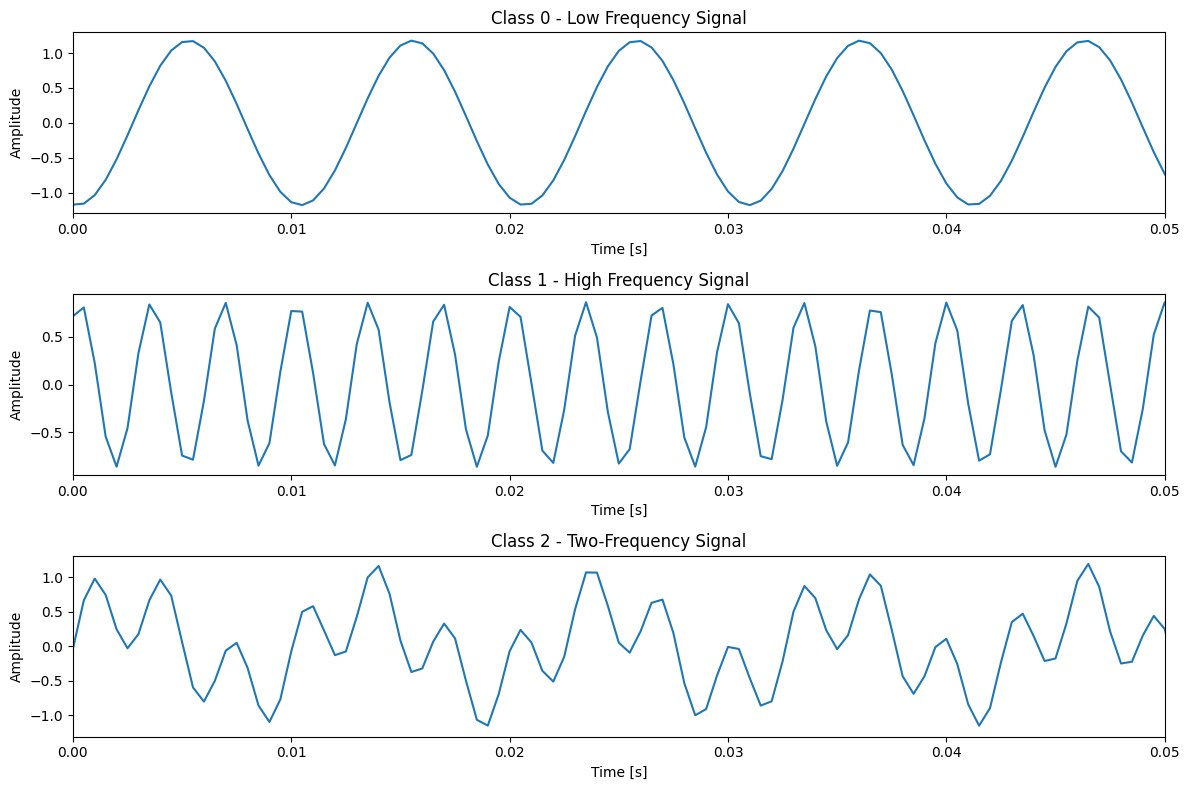

In [4]:
## Generate one representative signal from each class.

signal_0 = generate_signal(0, t)
signal_1 = generate_signal(1, t)
signal_2 = generate_signal(2, t)

## Visualize the three signal classes in the time domain.

plt.figure(figsize=(12, 8))

plt.subplot(3, 1, 1)
plt.plot(t, signal_0)
plt.title("Class 0 - Low Frequency Signal")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.xlim(0, 0.05)

plt.subplot(3, 1, 2)
plt.plot(t, signal_1)
plt.title("Class 1 - High Frequency Signal")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.xlim(0, 0.05)

plt.subplot(3, 1, 3)
plt.plot(t, signal_2)
plt.title("Class 2 - Two-Frequency Signal")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.xlim(0, 0.05)

plt.tight_layout()
plt.show()

***1.2 Dataset Creation***

In this section, we generate the complete dataset of clean signals using the signal generation function defined above. The dataset contains 2,100 signals, with 700 samples assigned to each of the three classes.

In [5]:
#At first, we will create N=2100 clean signals (without noise), 700 for each class.
signals = []
labels = []

samples_per_class = 700

for signal_class in range(3):

    for _ in range(samples_per_class):

        signal = generate_signal(signal_class, t)

        signals.append(signal)
        labels.append(signal_class)

signals = np.array(signals)
labels = np.array(labels)

print("Signals shape:", signals.shape)
print("Labels shape:", labels.shape)


Signals shape: (2100, 2000)
Labels shape: (2100,)


In [6]:
#check dataset

unique, counts = np.unique(labels, return_counts=True)

for class_label, count in zip(unique, counts):
    print(f"Class {class_label}: {count} signals")

Class 0: 700 signals
Class 1: 700 signals
Class 2: 700 signals


**1.3 Noise Generation**

In real-world applications, signals are often affected by noise.
In this section, we add Gaussian noise to the generated signals
and control its level using the Signal-to-Noise Ratio (SNR).

In [7]:
def add_noise(signal, snr_db):

    # Calculate signal power
    signal_power = np.mean(signal ** 2)

    # Convert SNR from dB to linear scale
    snr_linear = 10 ** (snr_db / 10)

    # Calculate required noise power
    noise_power = signal_power / snr_linear

    # Generate Gaussian noise
    noise = np.random.normal(
        0,
        np.sqrt(noise_power),
        size=signal.shape
    )

    # Add noise to the signal
    noisy_signal = signal + noise

    return noisy_signal

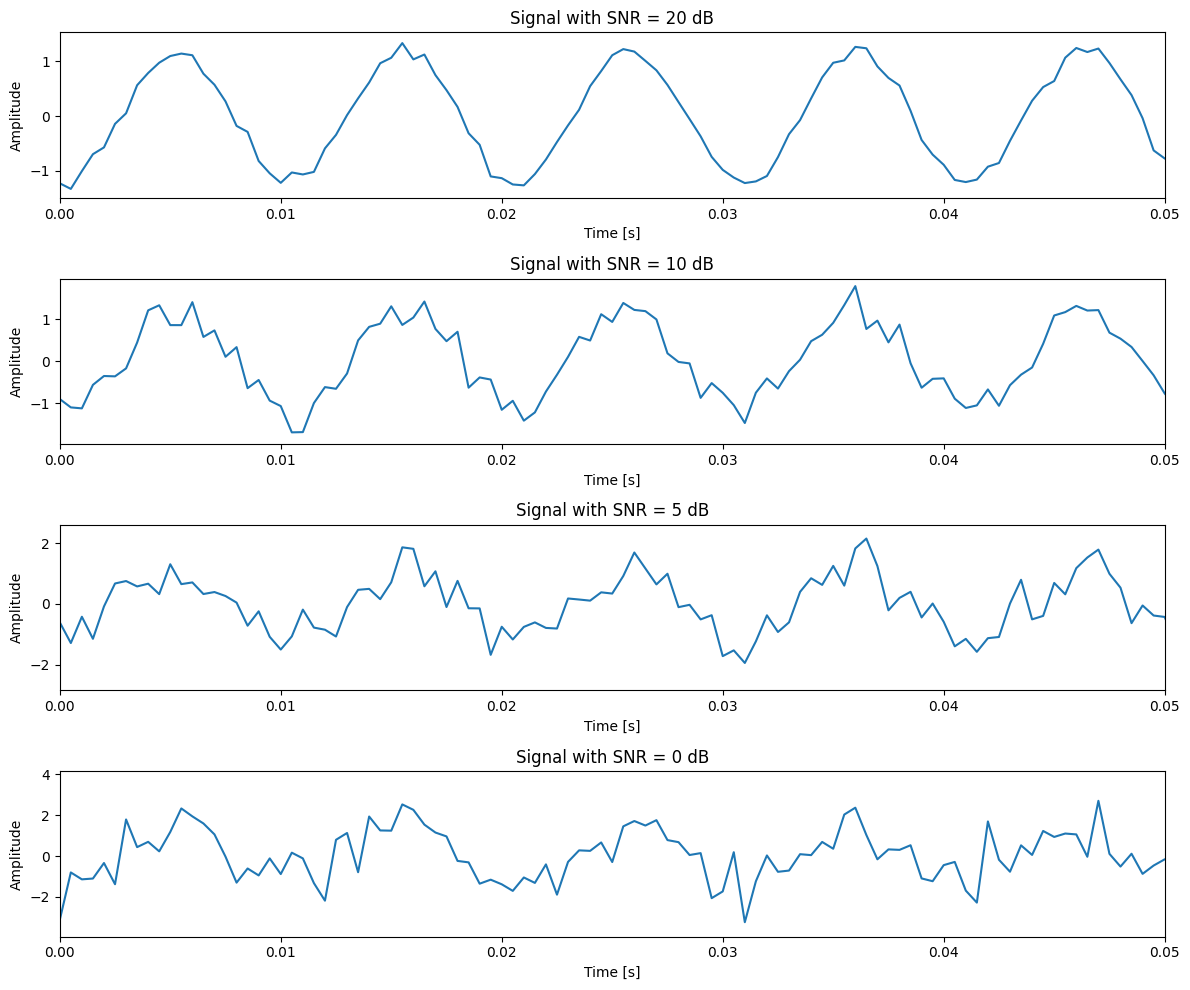

Requested SNR: 20 dB | Measured SNR: 19.59 dB
Requested SNR: 10 dB | Measured SNR: 10.35 dB
Requested SNR: 5 dB | Measured SNR: 5.14 dB
Requested SNR: 0 dB | Measured SNR: -0.20 dB


In [8]:
## Verify the noise generation and measured SNR.

snr_values = [20, 10, 5, 0]

noisy_signals = {}

for snr in snr_values:
    noisy_signals[snr] = add_noise(signal_0, snr)

plt.figure(figsize=(12, 10))

for i, snr in enumerate(snr_values):

    plt.subplot(4, 1, i + 1)
    plt.plot(t, noisy_signals[snr])
    plt.title(f"Signal with SNR = {snr} dB")
    plt.xlabel("Time [s]")
    plt.ylabel("Amplitude")
    plt.xlim(0, 0.05)

plt.tight_layout()
plt.show()

#check the SNR values

def calculate_snr(signal, noisy_signal):

    noise = noisy_signal - signal

    signal_power = np.mean(signal ** 2)
    noise_power = np.mean(noise ** 2)

    snr_db = 10 * np.log10(signal_power / noise_power)

    return snr_db

for snr in snr_values:

    measured_snr = calculate_snr(
        signal_0,
        noisy_signals[snr]
    )

    print(f"Requested SNR: {snr} dB | Measured SNR: {measured_snr:.2f} dB")


## Step 2: Frequency-Domain Analysis

In this section, the Fast Fourier Transform (FFT) is used to transform the signals from the time domain into the frequency domain. This allows us to examine the frequency content of the signals and identify the dominant frequency components of each class.

In [9]:
def compute_fft(signal, fs):

    N = len(signal)

    # Compute FFT
    fft_values = np.fft.fft(signal)

    # Compute corresponding frequency values
    frequencies = np.fft.fftfreq(N, 1/fs)

    # Keep only the positive frequencies
    positive = frequencies >= 0

    frequencies = frequencies[positive]
    fft_magnitude = np.abs(fft_values[positive]) / N

    return frequencies, fft_magnitude

***step 2.1: FFT Analysis of Clean Signals***

In this section, the FFT is applied to representative clean signals from
each class. The frequency spectra are visualized to identify the dominant
frequency components and examine the differences between the three signal
classes.

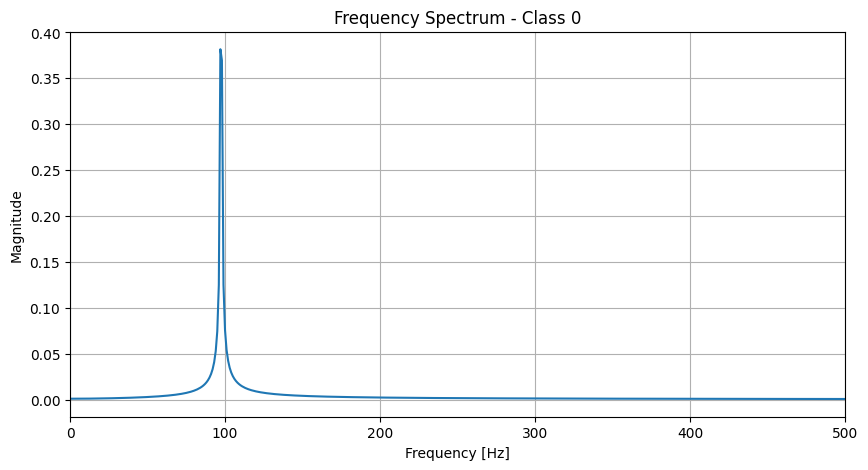

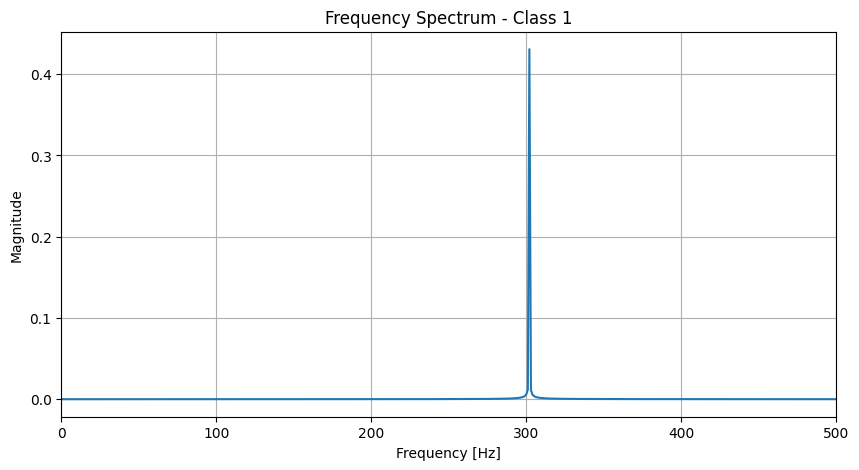

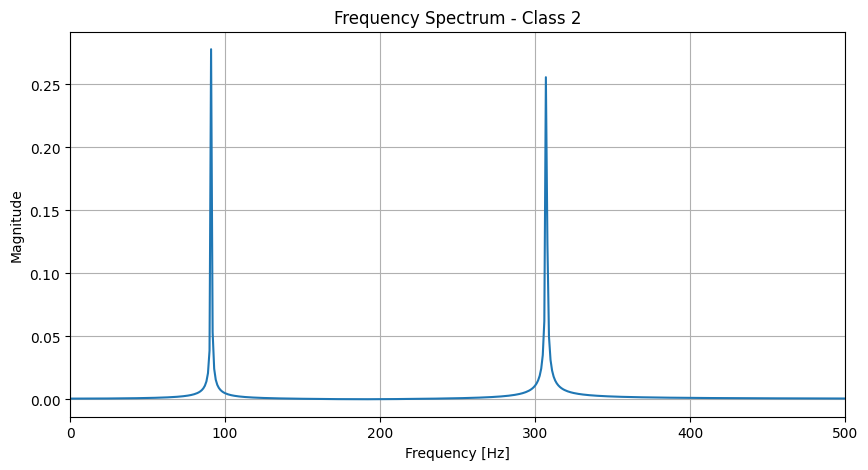

In [10]:
# Analyze Class 0
frequencies_0, magnitude_0 = compute_fft(signal_0, fs)

plt.figure(figsize=(10, 5))

plt.plot(frequencies_0, magnitude_0)

plt.title("Frequency Spectrum - Class 0")
plt.xlabel("Frequency [Hz]")
plt.ylabel("Magnitude")

plt.xlim(0, 500)

plt.grid()

plt.show()

# Analyze Class 1
frequencies_1, magnitude_1 = compute_fft(signal_1, fs)
plt.figure(figsize=(10, 5))

plt.plot(frequencies_1, magnitude_1)

plt.title("Frequency Spectrum - Class 1")
plt.xlabel("Frequency [Hz]")
plt.ylabel("Magnitude")

plt.xlim(0, 500)

plt.grid()

plt.show()

# Analyze Class 2
frequencies_2, magnitude_2 = compute_fft(signal_2, fs)
plt.figure(figsize=(10, 5))

plt.plot(frequencies_2, magnitude_2)

plt.title("Frequency Spectrum - Class 2")
plt.xlabel("Frequency [Hz]")
plt.ylabel("Magnitude")

plt.xlim(0, 500)

plt.grid()

plt.show()

***step 2.2: Frequency-Domain Analysis Under Noise***

In this section, we examine how different noise levels affect
the frequency spectrum of a representative Class 0 signal.
The FFT is applied to the same signal at several SNR levels
to observe how the spectral content changes as noise increases.

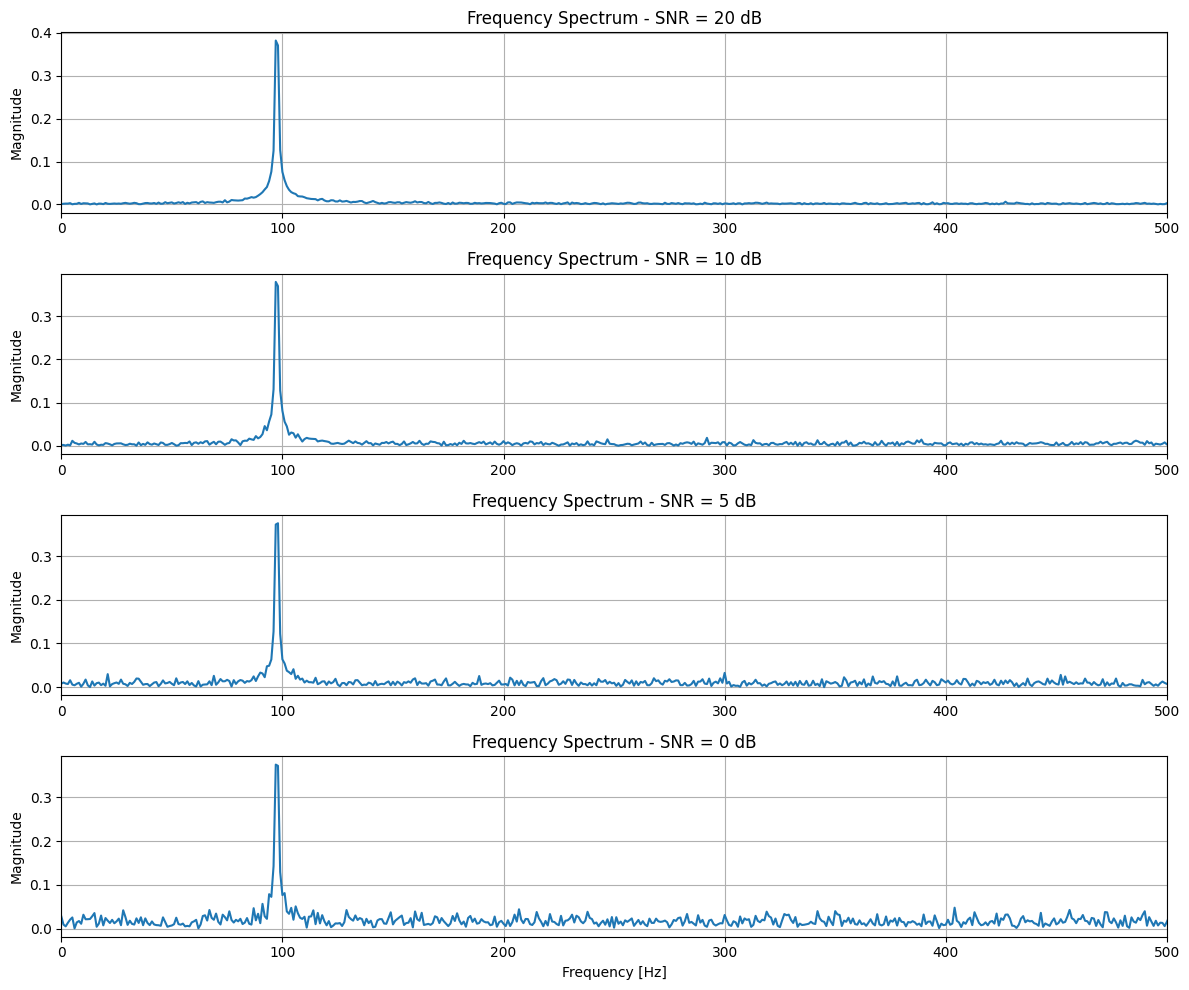

In [11]:
# Visualize the FFT of signals under different noise levels

plt.figure(figsize=(12, 10))

for i, snr in enumerate(snr_values):

    frequencies, magnitude = compute_fft(
        noisy_signals[snr],
        fs
    )

    plt.subplot(4, 1, i + 1)

    plt.plot(frequencies, magnitude)

    plt.title(f"Frequency Spectrum - SNR = {snr} dB")
    plt.ylabel("Magnitude")
    plt.xlim(0, 500)
    plt.grid()

plt.xlabel("Frequency [Hz]")
plt.tight_layout()
plt.show()

# **step 3 : Feature Extraction**


> In this step, each signal is represented by a vector of six numerical features extracted from the time and frequency domains. These features provide a compact representation of the signals for use in the machine learning models.



In [12]:
#Create function that will transform each signal into 6 features

def extract_features(signal, fs):

    # Time-domain features
    rms = np.sqrt(np.mean(signal ** 2))
    std = np.std(signal)
    peak_amplitude = np.max(np.abs(signal))

    # Frequency-domain features
    N = len(signal)

    fft_values = np.fft.rfft(signal)
    frequencies = np.fft.rfftfreq(N, 1/fs)

    magnitude = np.abs(fft_values)
    power = magnitude ** 2

    # Peak frequency
    peak_index = np.argmax(magnitude)
    peak_frequency = frequencies[peak_index]

    # Spectral energy
    spectral_energy = np.sum(power)

    # Spectral centroid
    spectral_centroid = (
        np.sum(frequencies * power)
        / np.sum(power)
    )

    # Spectral bandwidth
    spectral_bandwidth = np.sqrt(
        np.sum(
            ((frequencies - spectral_centroid) ** 2) * power
        )
        / np.sum(power)
    )

    return np.array ([
        rms,
        std,
        peak_amplitude,
        peak_frequency,
        spectral_energy,
        spectral_bandwidth
    ])



In [13]:
#check extract_features function on signal_0

features_0 = extract_features(signal_0, fs)

print(np.round(features_0, 3))
feature_names = [
    "RMS",
    "STD",
    "Peak_Amplitude",
    "Peak_Frequency",
    "Spectral_Energy",
    "Spectral_Bandwidth"
]

feature_vector = pd.DataFrame(
    [features_0],
    columns=feature_names
)

feature_vector

[8.35000000e-01 8.35000000e-01 1.18000000e+00 9.70000000e+01
 1.39296672e+06 1.84830000e+01]


,RMS,STD,Peak_Amplitude,Peak_Frequency,Spectral_Energy,Spectral_Bandwidth
0,0.834555,0.834554,1.180285,97.0,1.392967e+06,18.4831


In [14]:
#transform all 2100 signals to feature_vectors
all_features = []

for signal in signals:

    features = extract_features(signal, fs)
    all_features.append(features)

all_features = np.array(all_features)

print("Feature matrix shape:", all_features.shape)

df_features = pd.DataFrame(
    all_features,
    columns=feature_names
)

df_features["Label"] = labels

df_features.head()

Feature matrix shape: (2100, 6)


,RMS,STD,Peak_Amplitude,Peak_Frequency,Spectral_Energy,Spectral_Bandwidth,Label
0,0.626114,0.626114,0.884935,107.0,7.840386e+05,16.792101,0
1,0.651505,0.651500,0.921697,94.0,8.489274e+05,9.561608,0
2,0.648215,0.648213,0.916488,99.0,8.403702e+05,14.793757,0
3,0.647776,0.647773,0.916858,93.0,8.392348e+05,3.609297,0
4,0.788203,0.788202,1.114069,99.0,1.242533e+06,2.269252,0


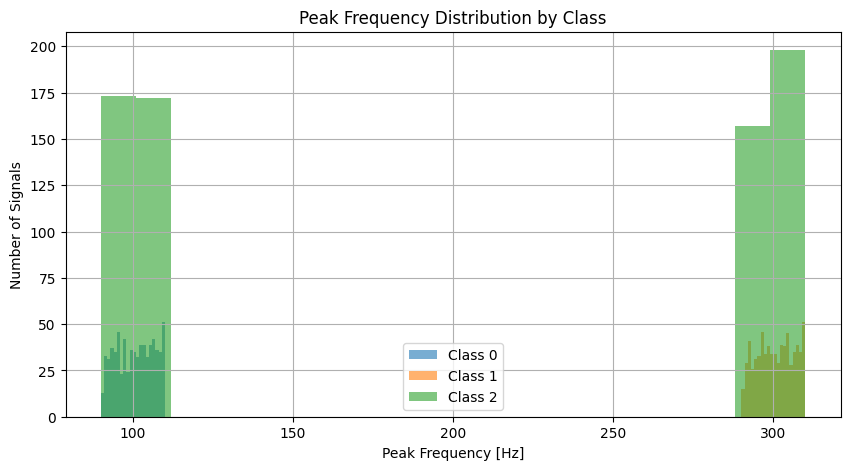

In [15]:
#Create gragh that show the Peak Frequency Distribution
plt.figure(figsize=(10, 5))

for label in [0, 1, 2]:

    class_data = df_features[
        df_features["Label"] == label
    ]

    plt.hist(
        class_data["Peak_Frequency"],
        bins=20,
        alpha=0.6,
        label=f"Class {label}"
    )

plt.xlabel("Peak Frequency [Hz]")
plt.ylabel("Number of Signals")
plt.title("Peak Frequency Distribution by Class")
plt.legend()
plt.grid()

plt.show()

# ***Step 4: Dataset Preprocessing***

In this section, the extracted features and class labels are prepared for machine learning. The dataset is checked for class balance, divided into training and test sets, and the features are standardized where required.

In [16]:
X = all_features
y = labels

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2100, 6)
y shape: (2100,)


In [17]:
#check if dataset is balanced
unique, counts = np.unique(y, return_counts=True)

for label, count in zip(unique, counts):
    print(f"Class {label}: {count} samples")

Class 0: 700 samples
Class 1: 700 samples
Class 2: 700 samples


***4.1 Train-Test Split***

The dataset is divided into training and test sets using an 80/20 split. Stratified sampling is used to preserve the same class distribution in both sets.

In [18]:
#Create training and test sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

#check size of training set anf test set
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

#check stratify
print("Training class distribution:")
print(np.bincount(y_train))

print("\nTest class distribution:")
print(np.bincount(y_test))

X_train shape: (1680, 6)
X_test shape: (420, 6)
y_train shape: (1680,)
y_test shape: (420,)
Training class distribution:
[560 560 560]

Test class distribution:
[140 140 140]


***4.2 Feature Scaling***

The extracted features have different scales and ranges. Therefore, we standardize the features using StandardScaler. The scaler is fitted only on the training data and then applied to both the training and test sets to avoid data leakage.

In [19]:

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
#fit only on training set, transform to both
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#check scaling
print("First 5 scaled samples:")
print(X_train_scaled[:5])

print("Mean of scaled training features:")
print(np.mean(X_train_scaled, axis=0))

print("\nStd of scaled training features:")
print(np.std(X_train_scaled, axis=0))

First 5 scaled samples:
[[ 0.60672726  0.60673609 -0.10649709  1.03462459  0.55058308 -0.73740689]
 [ 0.2338124   0.23382144 -0.55341139  1.05461423  0.15582801 -0.80491728]
 [-1.30535937 -1.30535974 -0.01998462 -1.07428261 -1.2372121   1.51352207]
 [-0.49610559 -0.49613493 -1.42812683 -1.04429814 -0.55217885 -0.61118837]
 [-1.24305896 -1.24308505  0.11556325 -1.07428261 -1.18819246  1.65208725]]
Mean of scaled training features:
[-3.53077356e-15 -4.30938354e-15 -3.77918596e-15 -4.65236315e-17
  1.85684801e-15 -5.00393378e-16]

Std of scaled training features:
[1. 1. 1. 1. 1. 1.]


In [20]:
df_train = pd.DataFrame(
    X_train_scaled,
    columns=feature_names
)

df_train["Label"] = y_train

df_train.head()

,RMS,STD,Peak_Amplitude,Peak_Frequency,Spectral_Energy,Spectral_Bandwidth,Label
0,0.606727,0.606736,-0.106497,1.034625,0.550583,-0.737407,1
1,0.233812,0.233821,-0.553411,1.054614,0.155828,-0.804917,1
2,-1.305359,-1.305360,-0.019985,-1.074283,-1.237212,1.513522,2
3,-0.496106,-0.496135,-1.428127,-1.044298,-0.552179,-0.611188,0
4,-1.243059,-1.243085,0.115563,-1.074283,-1.188192,1.652087,2


# ***Step 5: Baseline Machine Learning Model – Logistic Regression***

In this step, a Logistic Regression classifier is trained as a baseline model using the extracted features. The model is first evaluated on clean signals to establish a reference performance before testing its robustness to noise.

Actual labels:
[1 0 1 1 1 2 1 1 0 2 1 0 2 2 0 2 2 2 2 0]

Predicted labels:
[1 0 1 1 1 2 1 1 0 2 1 0 2 2 0 2 2 2 2 0]
Test Accuracy: 100.00%


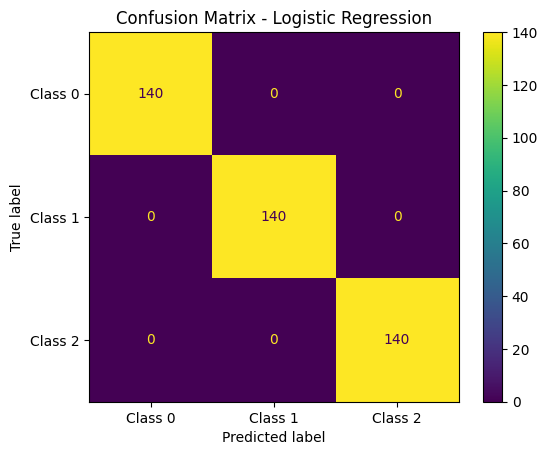

              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00       140
     Class 1       1.00      1.00      1.00       140
     Class 2       1.00      1.00      1.00       140

    accuracy                           1.00       420
   macro avg       1.00      1.00      1.00       420
weighted avg       1.00      1.00      1.00       420



In [21]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

#Sanity check
print("Actual labels:")
print(y_test[:20])

print("\nPredicted labels:")
print(y_pred[:20])

#Accuracy check
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy * 100:.2f}%")


#Confusion Matrix
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Class 0", "Class 1", "Class 2"]
)

disp.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["Class 0", "Class 1", "Class 2"]
))



# ***Step 6— Noise Robustness Evaluation***

In this step, the robustness of the Logistic Regression model is evaluated under different noise levels. The same test signals are used at each SNR level so that changes in accuracy can be attributed to the added noise.

In [22]:
# Define the SNR levels for robustness testing

snr_values = [20, 10, 5, 0]

print("SNR levels:", snr_values)

SNR levels: [20, 10, 5, 0]


In [23]:
#get the same test set as in step 4.1

from sklearn.model_selection import train_test_split

signals_train, signals_test, labels_train, labels_test = train_test_split(
    signals,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

#check
print("Test signals shape:", signals_test.shape)
print("Test labels shape:", labels_test.shape)

print("X_test shape:", X_test.shape)
print("signals_test shape:", signals_test.shape)

Test signals shape: (420, 2000)
Test labels shape: (420,)
X_test shape: (420, 6)
signals_test shape: (420, 2000)


SNR = 20 dB -> Shape: (420, 2000)
SNR = 10 dB -> Shape: (420, 2000)
SNR = 5 dB -> Shape: (420, 2000)
SNR = 0 dB -> Shape: (420, 2000)


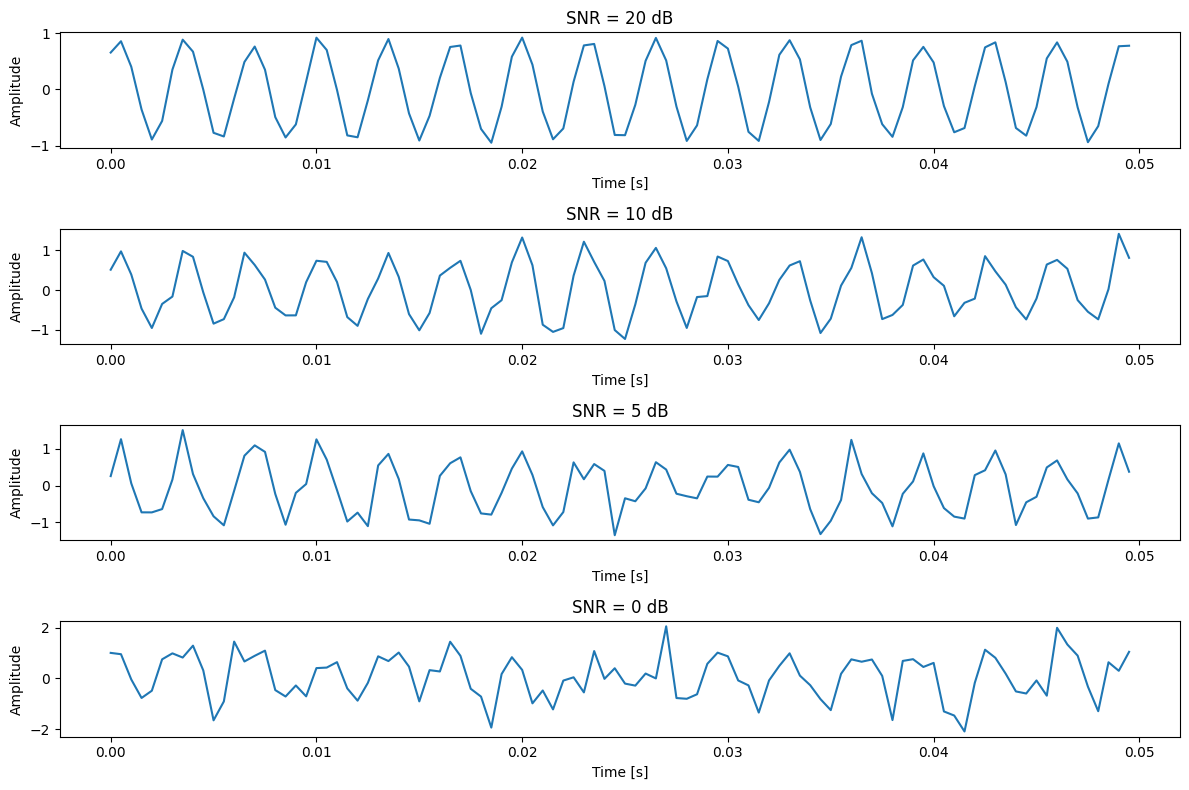

In [24]:
# Generate noisy versions of the test signals

# Generate noisy versions of the test signals

# Set random seed for reproducibility
np.random.seed(42)

noisy_test_signals = {}

for snr in snr_values:

    noisy_test_batch = np.array([
        add_noise(signal, snr)
        for signal in signals_test
    ])

    noisy_test_signals[snr] = noisy_test_batch

    print(
        f"SNR = {snr} dB -> "
        f"Shape: {noisy_test_batch.shape}"
    )

# Check that noise was added to the signals
signal_index = 0

plt.figure(figsize=(12, 8))

for i, snr in enumerate(snr_values):

    plt.subplot(4, 1, i + 1)

    plt.plot(
        t[:100],
        noisy_test_signals[snr][signal_index][:100]
    )

    plt.title(f"SNR = {snr} dB")
    plt.xlabel("Time [s]")
    plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()

In [25]:
# Extract features from noisy test signals

noisy_test_features = {}

for snr in snr_values:

    features = []

    for signal in noisy_test_signals[snr]:

        feature_vector = extract_features(signal, fs)
        features.append(feature_vector)

    noisy_test_features[snr] = np.array(features)

    print(
        f"SNR = {snr} dB -> "
        f"Feature matrix shape: {noisy_test_features[snr].shape}"
    )

SNR = 20 dB -> Feature matrix shape: (420, 6)
SNR = 10 dB -> Feature matrix shape: (420, 6)
SNR = 5 dB -> Feature matrix shape: (420, 6)
SNR = 0 dB -> Feature matrix shape: (420, 6)


In [26]:
# Scale noisy test features using the scaler fitted on clean training data

noisy_test_features_scaled = {}

for snr in snr_values:

    noisy_test_features_scaled[snr] = scaler.transform(
        noisy_test_features[snr]
    )

    print(
        f"SNR = {snr} dB -> "
        f"Scaled shape: {noisy_test_features_scaled[snr].shape}"
    )

SNR = 20 dB -> Scaled shape: (420, 6)
SNR = 10 dB -> Scaled shape: (420, 6)
SNR = 5 dB -> Scaled shape: (420, 6)
SNR = 0 dB -> Scaled shape: (420, 6)


In [27]:
# Evaluate Logistic Regression on noisy test data

noisy_predictions = {}
noisy_accuracies = {}

for snr in snr_values:

    predictions = model.predict(
        noisy_test_features_scaled[snr]
    )

    accuracy_noisy = accuracy_score(
        labels_test,
        predictions
    )

    noisy_predictions[snr] = predictions
    noisy_accuracies[snr] = accuracy_noisy

    print(
        f"SNR = {snr} dB -> "
        f"Accuracy: {accuracy_noisy * 100:.2f}%"
    )

SNR = 20 dB -> Accuracy: 97.14%
SNR = 10 dB -> Accuracy: 33.33%
SNR = 5 dB -> Accuracy: 33.33%
SNR = 0 dB -> Accuracy: 33.33%


[[  0   0 140]
 [  0   0 140]
 [  0   0 140]]


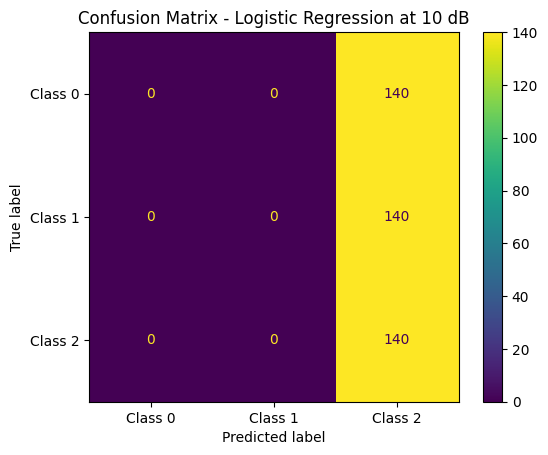

[[  0   0 140]
 [  0   0 140]
 [  0   0 140]]


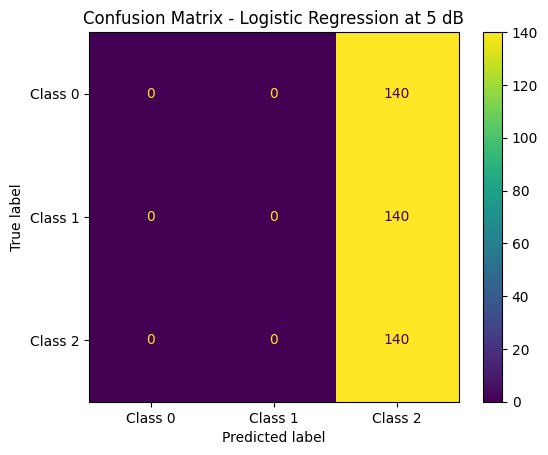

[[  0   0 140]
 [  0   0 140]
 [  0   0 140]]


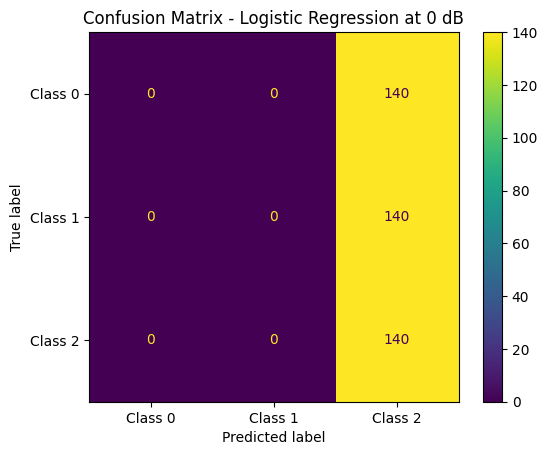

In [28]:
#check the results from the Logistic Regression on noisy test data

#Confusion Matrix 10dB
cm_10db = confusion_matrix(
    labels_test,
    noisy_predictions[10]
)

print(cm_10db)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_10db,
    display_labels=["Class 0", "Class 1", "Class 2"]
)

disp.plot()
plt.title("Confusion Matrix - Logistic Regression at 10 dB")
plt.show()

#Confusion Matrix 5dB
cm_5db = confusion_matrix(
    labels_test,
    noisy_predictions[5]
)

print(cm_5db)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_5db,
    display_labels=["Class 0", "Class 1", "Class 2"]
)

disp.plot()
plt.title("Confusion Matrix - Logistic Regression at 5 dB")
plt.show()


#Confusion Matrix 0dB
cm_0db = confusion_matrix(
    labels_test,
    noisy_predictions[0]
)

print(cm_0db)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_0db,
    display_labels=["Class 0", "Class 1", "Class 2"]
)

disp.plot()
plt.title("Confusion Matrix - Logistic Regression at 0 dB")
plt.show()

In [29]:
results_noise = pd.DataFrame({
    "SNR (dB)": snr_values,
    "Accuracy": [noisy_accuracies[snr] for snr in snr_values]
})

results_noise["Accuracy (%)"] = results_noise["Accuracy"] * 100

results_noise

,SNR (dB),Accuracy,Accuracy (%)
0,20,0.971429,97.142857
1,10,0.333333,33.333333
2,5,0.333333,33.333333
3,0,0.333333,33.333333


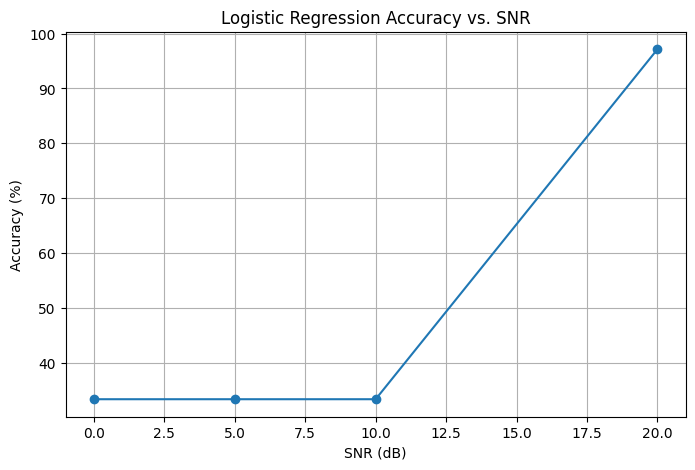

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_noise["SNR (dB)"],
    results_noise["Accuracy (%)"],
    marker="o"
)

plt.xlabel("SNR (dB)")
plt.ylabel("Accuracy (%)")
plt.title("Logistic Regression Accuracy vs. SNR")
plt.grid(True)

plt.show()

# ***Step 7: Analysis of Feature Behavior***

The initial robustness results show that Logistic Regression performs well on clean and high-SNR signals but degrades significantly as noise increases. In this step, we analyze how the extracted features change under different noise levels to better understand the source of this degradation.

In [31]:
#check which Features are affected from the noise

#take one signal
example_signal = signals_test[0]
example_label = labels_test[0]

print("Example signal label:", example_label)

#calculate the Features of the choosen signal
clean_features = extract_features(example_signal, fs)

print("Clean features:")
for name, value in zip(feature_names, clean_features):
    print(f"{name}: {value:.4f}")

#calculate the Features of the signal with diffrent level of SNR
print("\nNoisy features:")

for snr in snr_values:
    noisy_signal = noisy_test_signals[snr][0]
    features = extract_features(noisy_signal, fs)

    print(f"\nSNR = {snr} dB")

    for name, value in zip(feature_names, features):
        print(f"{name}: {value:.4f}")

Example signal label: 1
Clean features:
RMS: 0.6212
STD: 0.6212
Peak_Amplitude: 0.8785
Peak_Frequency: 307.0000
Spectral_Energy: 771761.2093
Spectral_Bandwidth: 0.0364

Noisy features:

SNR = 20 dB
RMS: 0.6235
STD: 0.6235
Peak_Amplitude: 1.0859
Peak_Frequency: 307.0000
Spectral_Energy: 777434.9575
Spectral_Bandwidth: 34.1085

SNR = 10 dB
RMS: 0.6519
STD: 0.6519
Peak_Amplitude: 1.4192
Peak_Frequency: 307.0000
Spectral_Energy: 849953.1886
Spectral_Bandwidth: 101.5568

SNR = 5 dB
RMS: 0.7134
STD: 0.7134
Peak_Amplitude: 1.8644
Peak_Frequency: 307.0000
Spectral_Energy: 1018038.6823
Spectral_Bandwidth: 163.9962

SNR = 0 dB
RMS: 0.8766
STD: 0.8766
Peak_Amplitude: 2.6957
Peak_Frequency: 307.0000
Spectral_Energy: 1537077.6430
Spectral_Bandwidth: 224.5797


***step 7.1 : Analysis peak_frequency***

The three signal classes contain different dominant frequency components, making Peak Frequency an important feature to examine. We analyze how this feature changes under different noise levels and whether it can explain the degradation in classification accuracy.

In [32]:
#check peak_frequency under diffrent level of SNR
peak_frequency_results = []

for snr in snr_values:
    features = noisy_test_features[snr]

    for class_label in [0, 1, 2]:
        class_features = features[labels_test == class_label]
        mean_peak_frequency = np.mean(class_features[:, 3])

        peak_frequency_results.append({
            "SNR": snr,
            "Class": class_label,
            "Mean Peak Frequency": mean_peak_frequency
        })

df_peak_frequency = pd.DataFrame(peak_frequency_results)

df_peak_frequency

,SNR,Class,Mean Peak Frequency
0,20,0,100.128571
1,20,1,300.607143
2,20,2,215.535714
3,10,0,100.128571
4,10,1,300.607143
5,10,2,215.535714
6,5,0,100.128571
7,5,1,300.607143
8,5,2,212.514286
9,0,0,100.128571


In [33]:
feature_comparison = []

for snr in snr_values:
    features = noisy_test_features[snr]

    for class_label in [0, 1, 2]:
        class_features = features[labels_test == class_label]

        mean_values = np.mean(class_features, axis=0)

        row = {
            "SNR": snr,
            "Class": class_label
        }

        for i, feature_name in enumerate(feature_names):
            row[feature_name] = mean_values[i]

        feature_comparison.append(row)

df_feature_comparison = pd.DataFrame(feature_comparison)

df_feature_comparison

,SNR,Class,RMS,STD,Peak_Amplitude,Peak_Frequency,Spectral_Energy,Spectral_Bandwidth
0,20,0,0.706991,0.706987,1.192184,100.128571,1.015096e+06,50.154470
1,20,1,0.715308,0.715305,1.205671,300.607143,1.035385e+06,35.912695
2,20,2,0.554453,0.554451,1.209175,215.535714,6.204766e+05,105.479396
3,10,0,0.737972,0.737952,1.662402,100.128571,1.105914e+06,145.074390
4,10,1,0.746320,0.746304,1.666513,300.607143,1.127294e+06,104.750285
5,10,2,0.578617,0.578604,1.509365,215.535714,6.757686e+05,153.768255
6,5,0,0.807101,0.807038,2.196472,100.128571,1.323322e+06,222.299895
7,5,1,0.816993,0.816950,2.226268,300.607143,1.351266e+06,166.027642
8,5,2,0.632700,0.632668,1.904970,212.514286,8.080663e+05,208.641752
9,0,0,0.994641,0.994536,3.223852,100.128571,2.010669e+06,286.026392


***7.2: Summary of Feature Analysis***

The Logistic Regression model achieved 100% accuracy on the clean test dataset, indicating that the original feature set provides sufficient information to distinguish between the three signal classes.

Under noisy conditions, the model achieved 97.14% accuracy at 20 dB SNR, but its performance decreased sharply to 33.33% at 10 dB, 5 dB, and 0 dB SNR.

The feature analysis showed that Spectral Bandwidth is strongly affected by increasing noise, while Peak Frequency remains relatively stable. However, Peak Frequency alone does not fully represent Class 2, which contains two distinct frequency components.

These results suggest that improving the representation of the frequency structure may be necessary to achieve better robustness to noise. Therefore, a second classification model and improved feature representations will be investigated in the following steps.


# ***Step 8: Random Forest Model Comparison***

In this step, a Random Forest classifier is evaluated using the same original six features and the same train-test split used for Logistic Regression. Keeping the feature representation unchanged allows us to examine whether changing the model alone can improve robustness to noise.

***step 8.1 Random Forest Classifier***

In this section, a Random Forest classifier is trained on the original feature set and evaluated first on clean test signals.

In [34]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

In [35]:
#create the model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)
rf_model.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

Random Forest Test Accuracy: 100.00%


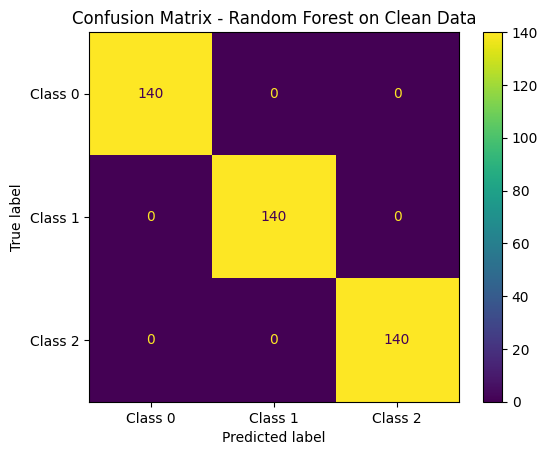

In [36]:
#check Accuracy with clear signals
rf_predictions = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_predictions)

print(f"Random Forest Test Accuracy: {rf_accuracy * 100:.2f}%")

rf_cm = confusion_matrix(y_test, rf_predictions)

from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=["Class 0", "Class 1", "Class 2"]
)

disp.plot()
plt.title("Confusion Matrix - Random Forest on Clean Data")
plt.show()

***step 8.2 : Noise Robustness***

The Random Forest model is evaluated on the same 420 test signals and using the same six original features as Logistic Regression. This provides a direct comparison between the two models under identical conditions.

In [37]:
rf_noisy_predictions = {}
rf_noisy_accuracies = {}

for snr in snr_values:
    predictions = rf_model.predict(noisy_test_features[snr])
    accuracy_noisy = accuracy_score(labels_test, predictions)

    rf_noisy_predictions[snr] = predictions
    rf_noisy_accuracies[snr] = accuracy_noisy

    print(
        f"SNR = {snr} dB -> "
        f"Accuracy: {accuracy_noisy * 100:.2f}%"
    )

SNR = 20 dB -> Accuracy: 95.95%
SNR = 10 dB -> Accuracy: 33.33%
SNR = 5 dB -> Accuracy: 33.33%
SNR = 0 dB -> Accuracy: 33.33%


# ***step 9: Feature Engineering V1***

The original feature set does not explicitly describe the energy distribution around the two characteristic frequency bands. In this step, additional frequency-domain features are introduced to better represent the spectral structure of the three classes, particularly the two frequency components of Class 2.

***step 9.1: New Features***

The original Peak Frequency feature represents only one dominant frequency, which may not fully describe Class 2 because it contains two frequency components. Therefore, we introduce additional features that measure the spectral energy around 100 Hz and 300 Hz, as well as the ratio between these two energy values.

In [38]:
#create new features: Energy Around 300Hz, Energy Around 100Hz, Energy Ratio

def get_band_energy(signal, fs, low_freq, high_freq):
    fft_values = np.fft.rfft(signal)
    frequencies = np.fft.rfftfreq(len(signal), 1/fs)

    power = np.abs(fft_values) ** 2

    band = (frequencies >= low_freq) & (frequencies <= high_freq)

    return np.sum(power[band])

#Energy Ratio
def get_energy_ratio(signal, fs):
    energy_100 = get_band_energy(signal, fs, 80, 120)
    energy_300 = get_band_energy(signal, fs, 280, 320)

    return energy_100 / (energy_300 + 1e-10)





***Step 9.2: Feature Extraction***

In this section, the new frequency-domain features are combined with the original six features to create an extended feature representation. The resulting representation contains nine features for each signal.

In [39]:
def extract_engineered_features(signal, fs):

    rms = np.sqrt(np.mean(signal ** 2))

    std = np.std(signal)

    peak_amplitude = np.max(np.abs(signal))

    N = len(signal)

    fft_values = np.fft.rfft(signal)
    frequencies = np.fft.rfftfreq(N, 1/fs)

    magnitude = np.abs(fft_values)
    power = magnitude ** 2

    peak_index = np.argmax(magnitude)
    peak_frequency = frequencies[peak_index]

    spectral_energy = np.sum(power)

    spectral_centroid = (
        np.sum(frequencies * power)
        / np.sum(power)
    )

    spectral_bandwidth = np.sqrt(
        np.sum(
            ((frequencies - spectral_centroid) ** 2) * power
        )
        / np.sum(power)
    )

    energy_100 = get_band_energy(
        signal, fs, 80, 120
    )

    energy_300 = get_band_energy(
        signal, fs, 280, 320
    )

    energy_ratio = energy_100 / (
        energy_300 + 1e-10
    )

    return [
        rms,
        std,
        peak_amplitude,
        peak_frequency,
        spectral_energy,
        spectral_bandwidth,
        energy_100,
        energy_300,
        energy_ratio
    ]

#define name for each feature
engineered_feature_names = [
    "RMS",
    "STD",
    "Peak_Amplitude",
    "Peak_Frequency",
    "Spectral_Energy",
    "Spectral_Bandwidth",
    "Energy_100Hz",
    "Energy_300Hz",
    "Energy_Ratio"
]

In [40]:
engineered_features = []

for signal in signals:
    features = extract_engineered_features(signal, fs)
    engineered_features.append(features)

engineered_features = np.array(engineered_features)

print(
    "Engineered feature matrix shape:",
    engineered_features.shape
)

Engineered feature matrix shape: (2100, 9)


In [41]:
df_engineered = pd.DataFrame(
    engineered_features,
    columns=engineered_feature_names
)

df_engineered["Label"] = labels

df_engineered.head()

,RMS,STD,Peak_Amplitude,Peak_Frequency,Spectral_Energy,Spectral_Bandwidth,Energy_100Hz,Energy_300Hz,Energy_Ratio,Label
0,0.626114,0.626114,0.884935,107.0,7.840386e+05,16.792101,7.767075e+05,160.141060,4850.146115,0
1,0.651505,0.651500,0.921697,94.0,8.489274e+05,9.561608,8.419240e+05,50.260081,16751.346149,0
2,0.648215,0.648213,0.916488,99.0,8.403702e+05,14.793757,8.335763e+05,124.684177,6685.501860,0
3,0.647776,0.647773,0.916858,93.0,8.392348e+05,3.609297,8.355182e+05,6.864792,121710.633571,0
4,0.788203,0.788202,1.114069,99.0,1.242533e+06,2.269252,1.240866e+06,4.465621,277870.933930,0


***step 9.3: Train-Test Split***

The engineered feature dataset is divided into training and test sets using the same 80/20 stratified split and random state as before. This keeps the experimental setup consistent across the different models and feature representations.

In [42]:
#Use the same spilt as we used in 4.1

X_engineered = engineered_features
y_engineered = labels

X_train_eng, X_test_eng, y_train_eng, y_test_eng = train_test_split(
    X_engineered,
    y_engineered,
    test_size=0.2,
    random_state=42,
    stratify=y_engineered
)

***step 9.4: scaling***

The engineered features have different numerical scales, so a new StandardScaler is fitted using only the engineered training data. The same scaler is then applied to the engineered test data.

In [43]:
engineered_scaler = StandardScaler()

X_train_eng_scaled = engineered_scaler.fit_transform(
    X_train_eng
)

X_test_eng_scaled = engineered_scaler.transform(
    X_test_eng
)

***step 9.5: Logistic Regression with Engineered Features***

A new Logistic Regression model is trained using the engineered feature representation. The model is first evaluated on clean signals before testing its robustness under noise.

In [44]:
engineered_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

engineered_model.fit(
    X_train_eng_scaled,
    y_train_eng
)

LogisticRegression(max_iter=1000, random_state=42)

In [45]:
#check on clean data
engineered_predictions = engineered_model.predict(
    X_test_eng_scaled
)

engineered_accuracy = accuracy_score(
    y_test_eng,
    engineered_predictions
)

print(
    f"Engineered Features Test Accuracy: "
    f"{engineered_accuracy * 100:.2f}%"
)

Engineered Features Test Accuracy: 100.00%


 **step 9.6: Noise Robustness - Logistic Regression**

 The Logistic Regression model with engineered features is evaluated on the same noisy test signals used previously. This allows us to determine whether the additional spectral features improve robustness to noise.

In [46]:
engineered_noisy_test_features = {}
for snr in snr_values:

    features = []

    for signal in noisy_test_signals[snr]:

        feature_vector = extract_engineered_features(
            signal,
            fs
        )

        features.append(feature_vector)

    engineered_noisy_test_features[snr] = np.array(features)

    print(
        f"SNR = {snr} dB -> "
        f"Feature matrix shape: "
        f"{engineered_noisy_test_features[snr].shape}"
    )

SNR = 20 dB -> Feature matrix shape: (420, 9)
SNR = 10 dB -> Feature matrix shape: (420, 9)
SNR = 5 dB -> Feature matrix shape: (420, 9)
SNR = 0 dB -> Feature matrix shape: (420, 9)


***9.7 Scaling the Noisy Features***

The noisy engineered features are transformed using the scaler fitted on the clean training data. No new scaling parameters are calculated from the noisy test data.

In [47]:
engineered_noisy_test_scaled = {}

for snr in snr_values:

    engineered_noisy_test_scaled[snr] = (
        engineered_scaler.transform(
            engineered_noisy_test_features[snr]
        )
    )

    print(
        f"SNR = {snr} dB -> "
        f"Scaled shape: "
        f"{engineered_noisy_test_scaled[snr].shape}"
    )

SNR = 20 dB -> Scaled shape: (420, 9)
SNR = 10 dB -> Scaled shape: (420, 9)
SNR = 5 dB -> Scaled shape: (420, 9)
SNR = 0 dB -> Scaled shape: (420, 9)


***9.8 Evaluation of the Engineered Logistic Regression Model***

The engineered Logistic Regression model is evaluated at each SNR level. Its accuracy is compared with the original Logistic Regression model to determine whether Feature Engineering V1 improves noise robustness.



In [48]:
engineered_noisy_predictions = {}
engineered_noisy_accuracies = {}

for snr in snr_values:

    predictions = engineered_model.predict(
        engineered_noisy_test_scaled[snr]
    )

    accuracy_noisy = accuracy_score(
        labels_test,
        predictions
    )

    engineered_noisy_predictions[snr] = predictions

    engineered_noisy_accuracies[snr] = accuracy_noisy

    print(
        f"SNR = {snr} dB -> "
        f"Accuracy: "
        f"{accuracy_noisy * 100:.2f}%"
    )

SNR = 20 dB -> Accuracy: 99.76%
SNR = 10 dB -> Accuracy: 33.33%
SNR = 5 dB -> Accuracy: 33.33%
SNR = 0 dB -> Accuracy: 33.33%


# ***step 10: Feature Engineering V2***

Feature Engineering V1 did not provide sufficient robustness at low SNR levels. In this step, we introduce relative spectral features that describe the proportion of energy and peak magnitude within the characteristic frequency bands, making the representation less dependent on the overall signal amplitude.


***step 10.1: new feature***

Instead of using only the absolute amount of spectral energy, we measure the relative contribution of the 100 Hz and 300 Hz frequency bands to the overall spectrum. We also introduce relative peak-magnitude features to better describe the strength of the dominant components within these bands.

In [49]:
#create Relative Band Energy feature

def get_relative_band_energy(signal, fs, low_freq, high_freq):

    fft_values = np.fft.rfft(signal)
    frequencies = np.fft.rfftfreq(len(signal), 1/fs)

    power = np.abs(fft_values) ** 2

    total_energy = np.sum(power)

    band = (
        (frequencies >= low_freq) &
        (frequencies <= high_freq)
    )

    band_energy = np.sum(power[band])

    relative_energy = band_energy / (total_energy + 1e-10)

    return relative_energy


In [50]:
#Calculate relative peak magnitude
def get_relative_peak_magnitude(
    signal,
    fs,
    low_freq,
    high_freq
):

    fft_values = np.fft.rfft(signal)
    frequencies = np.fft.rfftfreq(len(signal), 1/fs)

    magnitude = np.abs(fft_values)

    band = (
        (frequencies >= low_freq) &
        (frequencies <= high_freq)
    )

    band_peak = np.max(magnitude[band])

    total_magnitude = np.sum(magnitude)

    relative_peak = (
        band_peak /
        (total_magnitude + 1e-10)
    )

    return relative_peak

***step 10.2 : Feature Extractor***

In this step, we define a focused set of six features designed specifically to capture the spectral structure of the three signal classes. The new representation includes relative energy, relative peak magnitude, energy ratio, and Peak Frequency.

In [51]:
def extract_engineered_features_v2(signal, fs):

    N = len(signal)

    fft_values = np.fft.rfft(signal)
    frequencies = np.fft.rfftfreq(N, 1/fs)

    magnitude = np.abs(fft_values)
    power = magnitude ** 2

    # Peak frequency
    peak_index = np.argmax(magnitude)
    peak_frequency = frequencies[peak_index]

    # Relative energy
    relative_energy_100 = get_relative_band_energy(
        signal, fs, 80, 120
    )

    relative_energy_300 = get_relative_band_energy(
        signal, fs, 280, 320
    )

    # Relative peak magnitude
    relative_peak_100 = get_relative_peak_magnitude(
        signal, fs, 80, 120
    )

    relative_peak_300 = get_relative_peak_magnitude(
        signal, fs, 280, 320
    )

    # Energy ratio
    energy_ratio = (
        relative_energy_100 /
        (relative_energy_300 + 1e-10)
    )

    return [
        peak_frequency,
        relative_energy_100,
        relative_energy_300,
        relative_peak_100,
        relative_peak_300,
        energy_ratio
    ]

#Name for the features
engineered_feature_names_v2 = [
    "Peak_Frequency",
    "Relative_Energy_100Hz",
    "Relative_Energy_300Hz",
    "Relative_Peak_100Hz",
    "Relative_Peak_300Hz",
    "Energy_Ratio"
]

In [52]:
engineered_features_v2 = []

for signal in signals:

    features = extract_engineered_features_v2(
        signal,
        fs
    )

    engineered_features_v2.append(features)

engineered_features_v2 = np.array(
    engineered_features_v2
)

print(
    "Feature matrix shape:",
    engineered_features_v2.shape
)

Feature matrix shape: (2100, 6)


In [53]:
df_features_v2 = pd.DataFrame(
    engineered_features_v2,
    columns=engineered_feature_names_v2
)

df_features_v2["Label"] = labels

df_features_v2.head()

,Peak_Frequency,Relative_Energy_100Hz,Relative_Energy_300Hz,Relative_Peak_100Hz,Relative_Peak_300Hz,Energy_Ratio,Label
0,107.0,0.990650,0.000204,0.165362,0.000495,4850.143741,0
1,94.0,0.991750,0.000059,0.187346,0.000298,16751.317855,0
2,99.0,0.991916,0.000148,0.163834,0.000423,6685.497354,0
3,93.0,0.995571,0.000008,0.291830,0.000162,121709.145654,0
4,99.0,0.998659,0.000004,0.415455,0.000146,277863.202555,0


***step 10.3: Train-Test Split***

The V2 feature dataset is divided into training and test sets using the same stratified 80/20 split and random state as in the previous experiments.


In [54]:
X_engineered_v2 = engineered_features_v2
y_engineered_v2 = labels

X_train_v2, X_test_v2, y_train_v2, y_test_v2 = train_test_split(
    X_engineered_v2,
    y_engineered_v2,
    test_size=0.2,
    random_state=42,
    stratify=y_engineered_v2
)

***step 10.4: Feature Scaling***

A new StandardScaler is fitted using only the V2 training features. The fitted scaler is then applied to the training and test sets.

In [55]:
#create new scaler
scaler_v2 = StandardScaler()

X_train_v2_scaled = scaler_v2.fit_transform(
    X_train_v2
)

X_test_v2_scaled = scaler_v2.transform(
    X_test_v2
)

***10.5 Logistic Regression with Feature Engineering V2***

A new Logistic Regression model is trained using the V2 feature representation. The model is first evaluated on clean signals to establish its baseline performance.

In [56]:
model_v2 = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_v2.fit(
    X_train_v2_scaled,
    y_train_v2
)

LogisticRegression(max_iter=1000, random_state=42)

In [57]:
#check on clean data

predictions_v2 = model_v2.predict(
    X_test_v2_scaled
)

accuracy_v2 = accuracy_score(
    y_test_v2,
    predictions_v2
)

print(
    f"Feature Engineering V2 "
    f"Test Accuracy: {accuracy_v2 * 100:.2f}%"
)

Feature Engineering V2 Test Accuracy: 100.00%


 **step 10.6: Noise Robustness - Logistic Regression**

The V2 Logistic Regression model is evaluated on the same noisy test signals at all tested SNR levels. Its performance is compared with the original feature representation and Feature Engineering V1.

In [58]:
engineered_noisy_test_features_v2 = {}

for snr in snr_values:

    features = []

    for signal in noisy_test_signals[snr]:

        feature_vector = extract_engineered_features_v2(
            signal,
            fs
        )

        features.append(feature_vector)

    engineered_noisy_test_features_v2[snr] = np.array(
        features
    )

    print(
        f"SNR = {snr} dB -> "
        f"Shape: "
        f"{engineered_noisy_test_features_v2[snr].shape}"
    )

SNR = 20 dB -> Shape: (420, 6)
SNR = 10 dB -> Shape: (420, 6)
SNR = 5 dB -> Shape: (420, 6)
SNR = 0 dB -> Shape: (420, 6)


In [59]:
engineered_noisy_test_scaled_v2 = {}

for snr in snr_values:

    engineered_noisy_test_scaled_v2[snr] = (
        scaler_v2.transform(
            engineered_noisy_test_features_v2[snr]
        )
    )

***step 10.7: Evaluation of V2 Logistic Regression***

The classification accuracy is measured at each SNR level to determine whether the V2 feature representation improves robustness to noise.

In [60]:
noisy_predictions_v2 = {}
noisy_accuracies_v2 = {}

for snr in snr_values:

    predictions = model_v2.predict(
        engineered_noisy_test_scaled_v2[snr]
    )

    accuracy_noisy = accuracy_score(
        labels_test,
        predictions
    )

    noisy_predictions_v2[snr] = predictions
    noisy_accuracies_v2[snr] = accuracy_noisy

    print(
        f"SNR = {snr} dB -> "
        f"Accuracy: "
        f"{accuracy_noisy * 100:.2f}%"
    )

SNR = 20 dB -> Accuracy: 100.00%
SNR = 10 dB -> Accuracy: 100.00%
SNR = 5 dB -> Accuracy: 100.00%
SNR = 0 dB -> Accuracy: 33.57%


In [61]:
feature_comparison_v2 = pd.DataFrame({
    "SNR (dB)": snr_values,

    "Original Features (%)": [
        noisy_accuracies[snr] * 100
        for snr in snr_values
    ],

    "Engineered V1 (%)": [
        engineered_noisy_accuracies[snr] * 100
        for snr in snr_values
    ],

    "Engineered V2 (%)": [
        noisy_accuracies_v2[snr] * 100
        for snr in snr_values
    ]
})

feature_comparison_v2

,SNR (dB),Original Features (%),Engineered V1 (%),Engineered V2 (%)
0,20,97.142857,99.761905,100.000000
1,10,33.333333,33.333333,100.000000
2,5,33.333333,33.333333,100.000000
3,0,33.333333,33.333333,33.571429


***10.8 Random Forest with Feature Engineering V2***

The V2 feature representation is now evaluated using a Random Forest classifier. The model is trained on the same V2 training set and tested on both clean and noisy signals to determine whether the nonlinear model can further improve robustness.

In [62]:
#create new Random Forest
rf_model_v2 = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

#train the new model
rf_model_v2.fit(
    X_train_v2,
    y_train_v2
)

#check on clean data
rf_predictions_v2 = rf_model_v2.predict(
    X_test_v2
)

rf_accuracy_v2 = accuracy_score(
    y_test_v2,
    rf_predictions_v2
)

print(
    f"Random Forest V2 Clean Accuracy: "
    f"{rf_accuracy_v2 * 100:.2f}%"
)

#Noise Robustness
rf_noisy_predictions_v2 = {}
rf_noisy_accuracies_v2 = {}

for snr in snr_values:

    predictions = rf_model_v2.predict(
        engineered_noisy_test_features_v2[snr]
    )

    accuracy_noisy = accuracy_score(
        labels_test,
        predictions
    )

    rf_noisy_predictions_v2[snr] = predictions
    rf_noisy_accuracies_v2[snr] = accuracy_noisy

    print(
        f"SNR = {snr} dB -> "
        f"Accuracy: "
        f"{accuracy_noisy * 100:.2f}%"
    )

Random Forest V2 Clean Accuracy: 100.00%
SNR = 20 dB -> Accuracy: 100.00%
SNR = 10 dB -> Accuracy: 100.00%
SNR = 5 dB -> Accuracy: 100.00%
SNR = 0 dB -> Accuracy: 99.76%


# ***Step 11: Final Model Comparison and Robustness Test***

In this step, the performance of all model and feature combinations is compared across the tested SNR levels. A final robustness experiment is then performed using multiple noise realizations to examine the consistency of the Random Forest V2 results at 0 dB SNR.

In [63]:
final_comparison = pd.DataFrame({

    "SNR (dB)": snr_values,

    "Logistic - Original (%)": [
        noisy_accuracies[snr] * 100
        for snr in snr_values
    ],

    "Random Forest - Original (%)": [
        rf_noisy_accuracies[snr] * 100
        for snr in snr_values
    ],

    "Logistic - V1 (%)": [
    engineered_noisy_accuracies[snr] * 100
    for snr in snr_values
    ],


    "Logistic - V2 (%)": [
        noisy_accuracies_v2[snr] * 100
        for snr in snr_values
    ],

    "Random Forest - V2 (%)": [
        rf_noisy_accuracies_v2[snr] * 100
        for snr in snr_values
    ]
})

final_comparison

,SNR (dB),Logistic - Original (%),Random Forest - Original (%),Logistic - V1 (%),Logistic - V2 (%),Random Forest - V2 (%)
0,20,97.142857,95.952381,99.761905,100.000000,100.000000
1,10,33.333333,33.333333,33.333333,100.000000,100.000000
2,5,33.333333,33.333333,33.333333,100.000000,100.000000
3,0,33.333333,33.333333,33.333333,33.571429,99.761905


In [64]:
# Robustness test using multiple random seeds

robustness_seeds = [42, 123, 456, 789, 2026]

robustness_results = []

for seed in robustness_seeds:

    np.random.seed(seed)

    # Generate new noisy test signals at 0 dB SNR
    noisy_test_0db = np.array([
        add_noise(signal, 0)
        for signal in signals_test
    ])

    # Extract V2 features
    features_0db = []

    for signal in noisy_test_0db:
        feature_vector = extract_engineered_features_v2(signal, fs)
        features_0db.append(feature_vector)

    features_0db = np.array(features_0db)

    # Predict using the already trained Random Forest V2
    predictions_0db = rf_model_v2.predict(features_0db)

    # Calculate accuracy
    accuracy_0db = accuracy_score(labels_test, predictions_0db)

    robustness_results.append(accuracy_0db)

    print(
        f"Seed = {seed} -> "
        f"Accuracy = {accuracy_0db * 100:.2f}%"
    )

Seed = 42 -> Accuracy = 100.00%
Seed = 123 -> Accuracy = 100.00%
Seed = 456 -> Accuracy = 99.76%
Seed = 789 -> Accuracy = 100.00%
Seed = 2026 -> Accuracy = 100.00%


In [65]:
mean_accuracy = np.mean(robustness_results)
std_accuracy = np.std(robustness_results)

print(f"Mean Accuracy: {mean_accuracy * 100:.2f}%")
print(f"Standard Deviation: {std_accuracy * 100:.2f}%")

Mean Accuracy: 99.95%
Standard Deviation: 0.10%


In [66]:
robustness_df = pd.DataFrame({
    "Seed": robustness_seeds,
    "Accuracy": np.array(robustness_results) * 100
})

robustness_df

,Seed,Accuracy
0,42,100.000000
1,123,100.000000
2,456,99.761905
3,789,100.000000
4,2026,100.000000


# **Step 12: Detailed Analysis of the Final Model**

In this step, the final Random Forest V2 model is analyzed in greater detail to understand its performance at 0 dB SNR. The analysis includes a confusion matrix, classification report, feature importance analysis, and a comparison of model performance across noise levels.

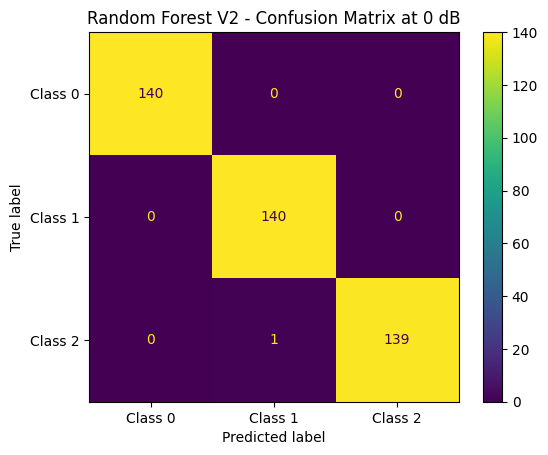

In [67]:
#Confusion Matrix 0dB
rf_cm_0db_v2 = confusion_matrix(
    labels_test,
    rf_noisy_predictions_v2[0]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm_0db_v2,
    display_labels=["Class 0", "Class 1", "Class 2"]
)

disp.plot()

plt.title(
    "Random Forest V2 - Confusion Matrix at 0 dB"
)

plt.show()

In [68]:
#Classification Report

from sklearn.metrics import classification_report, accuracy_score

print(
    classification_report(
        labels_test,
        rf_noisy_predictions_v2[0],
        target_names=[
            "Class 0",
            "Class 1",
            "Class 2"
        ],
        digits=4
    )
)

accuracy_0db = accuracy_score(
    labels_test,
    rf_noisy_predictions_v2[0]
)

print(f"Accuracy at 0 dB: {accuracy_0db * 100:.2f}%")

              precision    recall  f1-score   support

     Class 0     1.0000    1.0000    1.0000       140
     Class 1     0.9929    1.0000    0.9964       140
     Class 2     1.0000    0.9929    0.9964       140

    accuracy                         0.9976       420
   macro avg     0.9976    0.9976    0.9976       420
weighted avg     0.9976    0.9976    0.9976       420

Accuracy at 0 dB: 99.76%


In [69]:
#Feature Importance in Random Forest
feature_importance = pd.DataFrame({
    "Feature": engineered_feature_names_v2,
    "Importance": rf_model_v2.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

feature_importance


,Feature,Importance
1,Relative_Energy_100Hz,0.241905
2,Relative_Energy_300Hz,0.227040
5,Energy_Ratio,0.212135
3,Relative_Peak_100Hz,0.154425
4,Relative_Peak_300Hz,0.149395
0,Peak_Frequency,0.015100


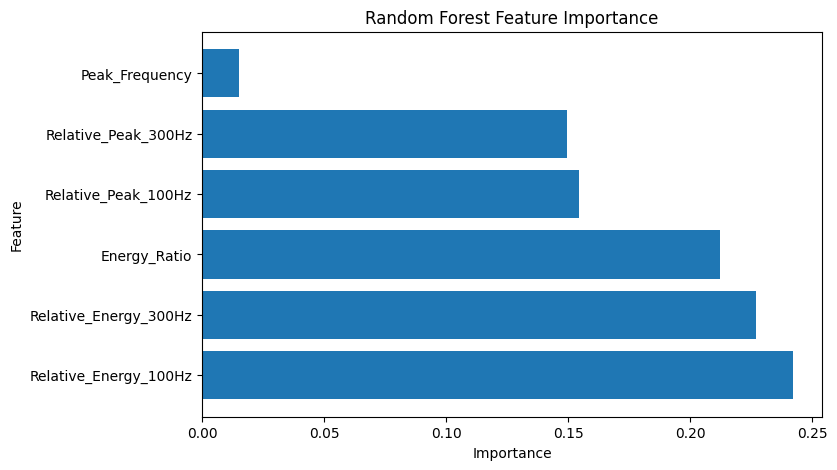

In [70]:
#Plot feature importance
plt.figure(figsize=(8, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.show()

***Final Model Performance Comparison***

The following plot summarizes the classification accuracy of all five model and feature combinations across the tested SNR levels. This provides a visual comparison of the effects of model selection and feature engineering on noise robustness.

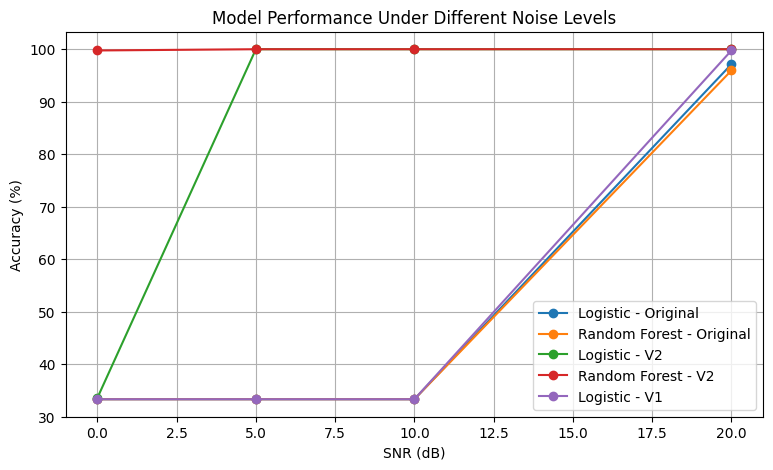

In [71]:
plt.figure(figsize=(9, 5))

plt.plot(
    snr_values,
    [noisy_accuracies[snr] * 100 for snr in snr_values],
    marker="o",
    label="Logistic - Original"
)

plt.plot(
    snr_values,
    [rf_noisy_accuracies[snr] * 100 for snr in snr_values],
    marker="o",
    label="Random Forest - Original"
)

plt.plot(
    snr_values,
    [noisy_accuracies_v2[snr] * 100 for snr in snr_values],
    marker="o",
    label="Logistic - V2"
)

plt.plot(
    snr_values,
    [rf_noisy_accuracies_v2[snr] * 100 for snr in snr_values],
    marker="o",
    label="Random Forest - V2"
)

plt.plot(
    snr_values,
    [engineered_noisy_accuracies[snr] * 100 for snr in snr_values],
    marker="o",
    label="Logistic - V1"
)

plt.xlabel("SNR (dB)")
plt.ylabel("Accuracy (%)")
plt.title("Model Performance Under Different Noise Levels")
plt.legend()
plt.grid(True)

plt.show()

# ***Step 13: Final Conclusions***

This section summarizes the main findings of the signal classification experiment and the effect of feature engineering on model robustness. The results are interpreted in the context of the synthetic dataset and the experimental conditions used in the project.

The goal of this project was to investigate the classification of synthetic signals using machine learning and to evaluate model robustness under different noise levels.

Using the original six features, both Logistic Regression and Random Forest achieved 100% accuracy on the clean test dataset, indicating that the extracted features provided sufficient information to distinguish between the three signal classes.

However, their performance decreased significantly under noisy conditions. At 20 dB SNR, Logistic Regression achieved 97.14% accuracy and Random Forest achieved 95.95%. Both models achieved 33.33% accuracy at 10 dB, 5 dB, and 0 dB SNR.

Feature Engineering V1 introduced additional absolute spectral-energy features around the 100 Hz and 300 Hz frequency bands. Logistic Regression with V1 achieved 99.76% accuracy at 20 dB SNR, but its performance remained limited at lower SNR levels.

Feature Engineering V2 introduced relative spectral-energy and peak-magnitude features designed to better represent the distribution of signal energy between the characteristic frequency bands.

With V2, Logistic Regression achieved 100% accuracy at 20 dB, 10 dB, and 5 dB SNR, but its accuracy decreased to 33.57% at 0 dB. Random Forest with V2 achieved 100% accuracy at 20 dB, 10 dB, and 5 dB, and 99.76% accuracy at 0 dB.
To further examine the consistency of the 0 dB result, the experiment was repeated using five different random seeds for generating the noise. Random Forest V2 achieved accuracies of 100%, 100%, 99.76%, 100%, and 100%. The mean accuracy was 99.95%, with a standard deviation of 0.10 percentage points.

Feature importance analysis showed that Relative_Energy_100Hz, Relative_Energy_300Hz, and Energy_Ratio were the most important features for Random Forest V2, while Peak_Frequency had a relatively small contribution.
Overall, the results indicate that feature engineering can substantially improve the robustness of signal classification models under noisy conditions. In this experiment, Random Forest combined with the V2 features achieved very high accuracy even at 0 dB SNR.

The project used synthetic signals with predefined frequency bands. Therefore, the results should be interpreted as a proof of concept and may not directly generalize to real-world RF or radar signals.


# **Step 14: Future Work**

This section presents possible extensions that could make the project more general and closer to real-world signal-processing applications.

Possible extensions include:

- Test the models on real measured RF signals instead of only synthetic data.
- Introduce additional types of noise and interference.
- Test a wider range of SNR values.
- Use more advanced signal-processing techniques for automatic spectral peak detection.
- Compare additional machine learning and deep learning approaches.
- Evaluate the models on signals with frequency ranges that differ from those used during training.